In [1]:
# -- Import Packages
#!/usr/bin/env python
%matplotlib inline  

#ipython magic to make wiphy module autoreload
%load_ext autoreload
%autoreload 2

#import packages
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import pandas as pd
import time
import scipy.integrate as spi
import os
from sklearn.metrics import auc 
import seaborn as sns
%matplotlib inline
import warnings
import seaborn as sns
from statannotations.Annotator import Annotator
from scipy.stats import mannwhitneyu

warnings.filterwarnings("ignore")


In [2]:
# -- Functions
def GetParams(parameters_df, ID, style = 'mode'):
    ''' 
    input:
        - data frame with parameter values as columns, individuals as rows
        - ID identifying individual of interest
        - style = 'mode' or 'mean' or 'SAEM' depending on which parameter values are preferred
    return:
        - dictionary with parameter names as key and parameter values as values
    '''
    i = ID
    cols = list(parameters_df)
    pid_params = parameters_df[parameters_df.id == i].copy()
    values = []
    keys = []
    for c in cols:
        if style in c:
            k = c.split('_')[0]
            keys.append(k)
            v = pid_params[c].values[0]
            values.append(v)
        for i,(v,k) in enumerate(zip(values, keys)):
            if 'log10' in k:
                values[i] = 10**v
                keys[i] = k.split('0')[1]

    params = dict(zip(keys, values))
    return params

In [3]:
def Simulate(func, param_order, param_dict, init, tend, N):
    '''
    input: 
        - func is a function that takes in the state variable, time and parameters and returns the derivative
        - params is a dictionary of the parameter values 
        - init is a dictionary of the initial condition to simulate from 
    return: 
        - trajectory simulated from init for tspan using func with given params
    '''
    # make parameter list in correct order
    params = []
    for k in param_order:
        params.append(param_dict[k])
    # build tspan
    tspan = np.linspace(0,tend,N)
    # incorporate E0
    init[5] = param_dict['E0']
    # simulate using scipy integrate
    y = spi.odeint(func, init, tspan, args = tuple(params))
    return tspan,y

# Set up initial condition
T_0 = 10**7
Ie_0 = 0;
Ip_0 = 0;
R_0 = 0;
V_0 = 0.075;
E_0 = 0;

init = [T_0, Ie_0, Ip_0, R_0, V_0, E_0]

#-------------------------------------#
# Write function for model simulation
#-------------------------------------#
def deriv(y, t, beta, phi, eta,gamma, delta,k, p,c,theta,h,r):
    T,Ie,Ip,R,V,E = y
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T -eta*R
    ddt_V = p*Ip-c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_V, ddt_E

param_order = ['beta', 'phi','eta','gamma', 
                         'delta','k','p','c','theta','h','r']


In [4]:
#-------------------------------------#
# Define baloxavir model
#-------------------------------------#
def derivBaloxavir(y, t, beta, phi, eta,gamma, delta,k,  p,c,theta,h,r,treat_start, treat_end, avg_efficacy):
    T,Ie,Ip,R,Vb,V,E = y
    
    if t > treat_start and t < treat_end:
        eps = avg_efficacy
    else:
        eps = 0
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T - eta*R
    ddt_Vb = 0
    ddt_V = (1-eps)*p*Ip - c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_Vb, ddt_V, ddt_E

param_order_treatment = ['beta', 'phi','eta','gamma', 
                         'delta','k','p','c','theta','h','r','Avgepsilon'
                        ]
                         #'treat_start', 'treat_end', '']




In [5]:
#-------------------------------------#
# Defining oseltamivir model
#-------------------------------------#
kcl = 2.079 #8 hour half-life of oseltamivir
def derivOseltamivir(y, t, beta, phi, eta, gamma, delta, k, p, c, theta, h, r, Avgepsilon, treat_start, treat_end):
   
    T,Ie,Ip,R,Vb,V,E = y
    
    if t > treat_start and t < treat_end:
        # treatment between start and end time
        eps = Avgepsilon
    elif t > treat_end:
        # exponential decay of efficacy after treatment ends
        # kcl = 2.079 --> 8 hour half-life of oseltamivir
        eps = (Avgepsilon * np.exp(-(kcl)*(t-treat_end)))/(Avgepsilon * (np.exp(-kcl * (t-treat_end))-1)+1)
    else:    
        # before treatment starts 
        eps = 0
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T - eta*R
    ddt_Vb = eps*p*Ip - (delta + k*E)*Vb
    ddt_V = (1-eps)*p*Ip - c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_Vb,ddt_V, ddt_E

param_order_oselt = ['beta', 'phi','eta','gamma', 
                     'delta','k','p','c',
                     'theta','h','r','Avgepsilon'
                     #'treat_start', 'treat_end'
                    ]


In [6]:
#-------------------------------------#
# Defining unbounded virus
#-------------------------------------#
def derivBUB(y, t, beta, phi, eta,gamma, delta,k,  p,c,theta,h,r):
    T,Ie,Ip,R,V,E = y
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R =  phi*Ip*T -eta*R
    ddt_Vb = p*Ip - delta*Vb - rho*Vb
    ddt_V = rho*Vb-c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_V, ddt_E

In [7]:
#-------------------------------------#
# Simulate treatment function
#-------------------------------------#
def SimulateTreatment(func, param_order, param_dict, initTreatment, tend, N, treat_start, treat_end, avg_efficacy):
    '''
    input: 
        - func is a function that takes in the state variable, time and parameters and returns the derivative
        - param_order: list - parameter names in the order expected by func
        - param_dict: a dictionary of individual-specific parameter values 
        - initTreatment: list - a dictionary of the initial condition to simulate from 
        - tend: float -- end time
        - N: int -- number of time points
        - treat_start: float -- Treatment start time
        - treat_end: float -- Treatment end time
    return: 
        - trajectory simulated from init for tspan using func with given params
    '''
    _
    # Make a copy so the original initial conditions are not modified
    #init = initTreatment.copy()
    
    # make parameter list in correct order
    params = []
    for k in param_order:
        params.append(param_dict[k])
        
    # add treatment parameters
    params.append(treat_start)
    params.append(treat_end)
    params.append(avg_efficacy)
    
    # build tspan
    tspan = np.linspace(0,tend,N)
    
    # incorporate E0
    # initTreatment[6] = param_dict['E0']
    
    # Set individual E0
    initTreatment[6] = param_dict['E0']
    
    # simulate using scipy integrate
    y = spi.odeint(func, 
                   initTreatment,   #init = initial conditions without Vb compartment
                   tspan, 
                   args = tuple(params))
    return tspan,y
    
Vb_0 = 0
initTreatment = [T_0, Ie_0, Ip_0, R_0, Vb_0, V_0, E_0]

In [15]:
# Read in placebo-treated volunteer data
#------------------------------#
# Monolix Results
#------------------------------#

#------------------------------#
# File: Fitting to viral dynamics model 
# Chosen (best-fit) model parameters: Fixed c, beta, h parameters - Pre-run ##
# Fixed Param: fraction of bound virus = f
#------------------------------#
M4a_shifted_Hill8_fixed_c_Owens = "~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/Test Models/Shifted Bounds - M4a/M4a_shifted_Hill8_fixed_c_Owens/IndividualParameters"
file_path = os.path.join(M4a_shifted_Hill8_fixed_c_Owens, "estimatedIndividualParameters.txt")

# Chosen (best-fit) estimated viral dynamics parameters read in 
parameters_df = pd.read_csv(file_path, header = 0, sep = ",")

# low-shed = blue; high-shed = red
# colorDict = {0:'cornflowerblue',1:'tab:red'}
#------------------------------#
# File: Fitting to Oselt-volunteers treated with 75mg - Run 1 (lowest AIC) ##
# estimated parameters for placebo and 75mg-oselt-treated cohorts 
#------------------------------#
# M4a_oselt_fit = "~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/Oselt_Treatment/M4a_shifted_Hill8_oseltamivir_f_0.75/Assessment/Assessment_001/Assessment_001/IndividualParameters"
#oselt_file_path = os.path.join(M4a_oselt_fit, "estimatedIndividualParameters.txt")

# oselt-treated parameters read in 
# parameters_df = pd.read_csv(oselt_file_path, header = 0, sep = ",")

# volunteer observed vl data
untreated_df = pd.read_csv("~/OneDrive - Fred Hutch Cancer Center/IAV Data/Data_IAV Model/FLU_ALL_un_censored.csv")

IDs = untreated_df.ID.unique()
#------------------------------#
# volunteer observed vl data
#------------------------------#

# placebo n = 44 and oseltamivir (75mg) treated n = 39 volunteers; totalling n = 83 volunteers
#oselt_placebo_df = pd.read_csv("~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/placebo_75oselt.csv")
#oselt_df = pd.read_csv("~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/treated_75oselt.csv")

#IDs = oselt_placebo_df.ID.unique()

# treated = 1; placebo = 0
#colorDict = {0:'dodgerblue',1:'tab:orange'}

len(IDs)       # n = 44 placebo-volunteers for simulation 
print(untreated_df)
print(parameters_df)


        ID      Time  Viral_Titer  censored  cat_strain  cat_control
0       4A  0.000000         0.00         1           1            0
1       4A  0.947917         1.50         0           1            0
2       4A  1.438889         4.00         0           1            0
3       4A  1.945833         5.50         0           1            0
4       4A  2.433333         3.75         0           1            0
..     ...       ...          ...       ...         ...          ...
482  73B-B  4.677778         1.75         0           0            0
483  73B-B  5.700000         0.00         0           0            0
484  73B-B  6.679167         1.16         0           0            0
485  73B-B  7.688889         0.83         0           0            0
486  73B-B  8.634028         0.00         1           0            0

[487 rows x 6 columns]
        id  log10beta_SAEM  delta_SAEM  log10p_SAEM  c_SAEM  gamma_SAEM  \
0       4A        -5.64272     1.10239      1.36365      15     6.30362  

### Calculate difference between placebo and baloxavir treated group
##### Calculate difference = Observed placebo - observed/literature mean balox
### Simulating clinical trial:
##### -Loop over efficacy rate from 50% - 100% - at intervals of 5%
##### -Run simulation - within each loop: calculate the difference between placebo and treated group at days 0 - 5 post treatment for each individual
##### -Calculate the R^2 comparing model to data
##### -Plot R^2 as a function of efficacy 

In [311]:
# Simulate placebo/viral dynamics model and baloxavir treated model
# compare the simulated placebo and balox-treated difference with the observed placebo balox-treated (mean) data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt                    # for plotting 
from sklearn.metrics import r2_score               # for calculating R^2 

# ---------------------------------
# Observed data: NEJM Digitized Mean Data
# ---------------------------------
'''
"The mean (±SD) viral loads on day 1 (before the initiation of the trial regimen) 
were 5.79±1.87 log10 50% tissue-culture (TCID50) per milliliter in the baloxavir group,
5.56±1.89 log10 50% tissue-culture infective dose (TCID50) per milliter in the placebo group,
5.94±1.69 log10 TCID50 per milliliter in the oseltamivir group

LOD = 0.7 TCID50 
'''
# Adjust the timing of enrollment/baseline measurement to align untreated trajectories with placebo group
# Hayden 2018 NEJM (approximated) time points of change from baseline in Phase 3 trial (Figure 3):

time_points = np.array([0, 1, 2, 3, 4, 
                        #5, 6, 9
                       ])       # Day 0 = Day 1 before the initiation of the trial regimen in NEJM paper

# -----------------
# Digitized data
# -----------------
observed_Placebo_Mean = (np.array([0, -1.2,-2.9,-3.34,-4.47
                                  # , -4.49, -4.88
                                  ]))
observed_Balox_Mean   = (np.array([0, -4.4, -4.9, -4.5, -4.9
                                   #, -4.6, -5.0
                                  ]))       # greater viral load reduction for baloxavir by day 1
observed_Oselt_Mean   = np.array([0, -2.5, -4.2, -4.6, -5, -4.8, -5.2])

# -----------------
# Given NEJM data: mean viral load on day 1 (before the initiation of the trial regimen):
# reverting to viral load, if needed
# -----------------
#placebo_baseline = 5.56          # SD: +/- 1.89 
#oselt_baseline = 5.94            # SD: +/- 1.69
#balox_baseline = 5.79            # SD: +/1 1.87

# ----------
# If needed: Revert back to viral load - Digitized NEJM data 
# ----------
#Placebo_VL = placebo_baseline + Placebo_Mean 
#Oselt_VL = oselt_baseline + Oselt_Mean 
#Balox_VL = balox_baseline + Balox_Mean 

# -----------------
# Observed Data: Calculate the difference of observed data
# vl change of balox - placebo
# ----------------
observed_difference = observed_Balox_Mean - observed_Placebo_Mean    
observed_diff = (-observed_Balox_Mean - (-observed_Placebo_Mean))
# results should be the same for the two above expressions

# subtraction order of operating but should yield the same results
print("\n NEJM Observed Baloxavir - Placebo Mean Difference:")
for day, diff in zip(time_points, observed_difference):
    print(f"Day {day}: {diff:.3f}")

print("\n NEJM Observed -Balox - (-Placebo) Mean difference:")
for day, diff in zip(time_points, observed_diff):
    print(f"Day {day}: {diff:.3f}")

# appending the calculated results into one array with col1 = days post treatment 
#observed_appended = np.column_stack((time_points, observed_difference))
#print(observed_appended)

print(observed_Placebo_Mean)


 NEJM Observed Baloxavir - Placebo Mean Difference:
Day 0: 0.000
Day 1: -3.200
Day 2: -2.000
Day 3: -1.160
Day 4: -0.430

 NEJM Observed -Balox - (-Placebo) Mean difference:
Day 0: 0.000
Day 1: 3.200
Day 2: 2.000
Day 3: 1.160
Day 4: 0.430
[ 0.   -1.2  -2.9  -3.34 -4.47]


#### Results
#### NEJM Observed Balox - Placebo Mean difference:
##### Day 1: 0.000                # no distinction between the two arms
##### Day 2: -3.200               # baloxavir yielded a greater vl reduction
##### Day 3: -2.000
##### Day 4: -1.160
##### Day 5: -0.430
##### Day 6: -0.110
##### Day 9: -0.120

#### MODEL SIMULATIONS
# -----------------
##### Next, we simulate and determine the change in viral load of the placebo and balox simulations
##### Balox simulation: looping efficacy through 50% - 99%
##### Calculate the difference of the simulated results
##### Store the difference of simulated placebo - simulated balox
# -----------------

In [314]:
import numpy as np
import pandas as pd

IDs = untreated_df.ID.unique()

# Define simulation function with fixed parameter f (fraction of bound virus contributing to total viral load)
def simulate_placebo_balox(
    IDs,
    parameters_df,
    days_to_analyze = [0, 1, 2, 3, 4,
                       #5, 6, 9
                      ],
    Avgepsilon_range = np.append(np.arange(0.5, 1, 0.05), 0.99) #[0.50, 0.75, 0.99] at 5% intervals
    #f = 0.75      #fixed proportion of bound virus  --> Not needed for placebo nor balox models
):
    """
    Simulate individual viral-load trajectories under placebo/untreated
    conditions and baloxavir treatment across different efficacy levels.

    Viral-load changes are calculated for each individual relative to
    their own peak viral load (baseline), following the same procedure
    used in the individual viral-load plotting code.

    Parameters
    ----------
    IDs : array-like -- Individual placebo and balox-treated volunteers IDs.
    
    parameters_df : pandas.DataFrame - Individual parameter estimates used by GetParams().

    days_to_analyze : list
        Days after individual baseline/peak viral load to calculate
        viral-load change.

    avg_efficacy_range : list
        Baloxavir efficacy values to evaluate.
        Default: [0.50 --> 0.99]

    Returns
    -------
    balox_placebo_results : dict - Dictionary containing one DataFrame for each day.
        Rows:
            Placebo
            Baloxavir
        Columns:
            efficacy levels (50% --> 99%) at increments of 5%
        Values:
            Viral-load reduction from individual's baseline.

    individual_reductions: dict
         nested by f, then efficacy --> each df has days as rows and treatment outcomes as columns
    """
    # ---------------------------------------------------------
    # initialize a dictionary to store calculated reductions
    # ---------------------------------------------------------
    individual_reductions= {}
    

    # ---------------------------------------------------------
    # BALOX Treatment settings
    # ---------------------------------------------------------
    treat_start = 0
    treat_end_B = 3.5

    # ---------------------------------------------------------
    # Set up results matrices
    # ---------------------------------------------------------
    efficacy_labels = [
        f'{int(eps * 100)}%'
        for eps in Avgepsilon_range
    ]

    balox_placebo_results = {}

    for day in days_to_analyze:

        balox_placebo_results[f'Day {day}'] = pd.DataFrame(
            index = ['Placebo', 
                     'Baloxavir',
                     'Simulated Difference'],
            columns = efficacy_labels,
            dtype = float
        )

    # ---------------------------------------------------------
    # Loop through each efficacy level
    # ---------------------------------------------------------
    #Avgepsilon_range = 0
    for efficacy, efficacy_label in zip(
        Avgepsilon_range,
        efficacy_labels
    ):

        # Store individual-level VL reductions
        placebo_reductions_by_day = {
            day: [] for day in days_to_analyze
        }

        balox_reductions_by_day = {
            day: [] for day in days_to_analyze
        }

        # -----------------------------------------------------
        # Loop through individuals via IDs
        # -----------------------------------------------------

        for ID in IDs:

            # -------------------------------------------------
            # Get individual's parameter estimates
            # -------------------------------------------------
            params_dict = GetParams(
                parameters_df,
                ID,
                style='mode'
            )

            # -------------------------------------------------
            # PLACEBO simulation
            # -------------------------------------------------
            t, y = Simulate(
                deriv,            # function
                param_order,      # parameters list
                params_dict,      # parameters 
                init,             # initial conditions
                40,              
                10000
            )

            # -------------------------------------------------
            # PLACEBO: Determine individual's PLACEBO'S peak viral load
            # -------------------------------------------------
            V_untreated = np.log10(
                np.maximum(y[:, 4], 0.1)
            )
            # Placebo specific peak of individual
            pk_ind = np.argmax(V_untreated)
            
            # time of vl-peak
            tpk = t[pk_ind]

            # Placebo baseline viral load individual-specific baseline
            V0_untreated = V_untreated[pk_ind]

            # -------------------------------------------------
            # BALOX: treatment timing
            # -------------------------------------------------
            treat_start_temp = tpk + treat_start
            treat_end_B_temp = tpk + treat_end_B

            # -------------------------------------------------
            # BALOX: Simulate specified efficacy
            # (func, param_order, param_dict, init, tend, N, treat_start, treat_end, avg_efficacy)
            # -------------------------------------------------
            ttB, ytB = SimulateTreatment(derivBaloxavir, 
                                         param_order, 
                                         params_dict,
                                         initTreatment, 
                                         40,             
                                         10000,           
                                         treat_start_temp, 
                                         treat_end_B_temp, 
                                         efficacy
                                        )
        
            # Total baloxavir viral load; note: ytB[:,4] = Vb = 0 --> no bound virus considered
            V_B = np.log10(np.maximum(ytB[:,4] + ytB[:,5], 0.01))
            
            # peak viral load
            balox_baseline_idx = np.argmin(np.abs(ttB- tpk))
            
            # baseline viral load of balox
            V0_B = V_B[balox_baseline_idx]

            # -------------------------------------------------
            # Calculate VL reduction at each day
            # -------------------------------------------------
            for day in days_to_analyze:
                # --------------------------------------------
                # PLACEBO reduction
                # --------------------------------------------
                target_time_p = tpk + day

                placebo_idx = np.argmin(np.abs(t - target_time_p))

                placebo_vl = V_untreated[placebo_idx]
                
                #Placebo: Viral load reduction = vl - initial viral load 
                placebo_change = (placebo_vl - V0_untreated)

                placebo_reductions_by_day[day].append(placebo_change)


                # --------------------------------------------
                # BALOXAIVR reduction
                # --------------------------------------------
                target_time_B = tpk + day

                balox_idx = np.argmin(np.abs(ttB - target_time_B))

                balox_vl = V_B[balox_idx]

                # Balox: Viral load reduction = viral load - initial viral load
                balox_change = (balox_vl - V0_B)

                balox_reductions_by_day[day].append(balox_change)


                # --------------------------------------------
                # Store individual's reduction inside defined dictionary
                # --------------------------------------------
                individual_reductions[efficacy_label] = {
                    'Placebo': placebo_reductions_by_day.copy(),
                    'Baloxavir': balox_reductions_by_day.copy()
                }

        # -----------------------------------------------------
        # Calculate mean reduction across individuals
        # -----------------------------------------------------
        for day in days_to_analyze:
    
            # determine mean
            placebo_mean = np.mean(placebo_reductions_by_day[day])
            balox_mean = np.mean(balox_reductions_by_day[day])
            
            # Using the calculated reductions
            # store the placebo mean 
            balox_placebo_results[f'Day {day}'].loc['Placebo', efficacy_label] = placebo_mean

            # store the treated balox mean
            balox_placebo_results[f'Day {day}'].loc['Baloxavir', efficacy_label] = balox_mean

        # -----------------------------------------------------
        # Calculate difference between placebo and balox-treated 
        # difference: balox reduction - placebo reduction
        # -----------------------------------------------------
            # calculate the difference: 'balox - placebo' same setup as the observed difference 
            simulated_difference =  balox_mean - placebo_mean  

            # store the calculation
            balox_placebo_results[f'Day {day}'].loc['Simulated Difference', efficacy_label] = simulated_difference

    return balox_placebo_results, individual_reductions

In [349]:
# Run the above looped-function to determine R^2
# plot resulting R^2 as a function of efficacy 

balox_placebo_results, individual_reductions = simulate_placebo_balox(
    IDs = IDs,
    parameters_df = parameters_df,
    days_to_analyze = [
        0, 1, 2, 3, 4
        #, 5, 6
        #, 9
                      ],
    Avgepsilon_range = np.append(np.arange(0.5, 1.01, 0.05), 0.99)
            #np.append(np.arange(0.5, 1, 0.05), 0.99)            # increment by 5%, from 50% to 99%
)



#balox_placebo_results
print(balox_placebo_results['Day 0'])
print(balox_placebo_results['Day 1'])
print(balox_placebo_results['Day 2'])
print(balox_placebo_results['Day 3'])
print(balox_placebo_results['Day 4'])
#print(balox_placebo_results['Day 5'])
#print(balox_placebo_results['Day 6'])
#print(balox_placebo_results['Day 9'])


                      50%  55%  60%  65%  70%  75%  80%  85%  90%  95%  100%  \
Placebo               0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0   
Baloxavir             0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0   
Simulated Difference  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0   

                      99%  
Placebo               0.0  
Baloxavir             0.0  
Simulated Difference  0.0  
                           50%       55%       60%       65%       70%  \
Placebo              -0.854089 -0.854089 -0.854089 -0.854089 -0.854089   
Baloxavir            -1.544985 -1.641817 -1.747392 -1.863647 -1.993354   
Simulated Difference -0.690896 -0.787728 -0.893303 -1.009558 -1.139265   

                           75%       80%       85%       90%       95%  \
Placebo              -0.854089 -0.854089 -0.854089 -0.854089 -0.854089   
Baloxavir            -2.140682 -2.312347 -2.517015 -2.770775 -3.132844   
Simulated Difference -1.286593 -1.458258 -1.6629

In [369]:
# Store results ('balox_placebo_results') in a csv file
# save the simulated difference results to a .csv file
# convert the yielded results from dictionary ('dict') into dataframes ('df')

#print(balox_placebo_results.keys())         # resulting keys: Day 0, Day 1, Day 2, Day 3, Day 4
#print(individual_reductions.keys())         # resulting keys: 50%, 55%, ...., 100%, 99%

import pandas as pd

# loop through the days to save as a df
all_days_results = []

days_to_analyze = [0, 1, 2, 3, 4,
                       #5, 6, 9
                      ],

# Loop through each day in the results dictionary
for day_label, day_df in balox_placebo_results.items():
   
    # Convert efficacy percentages from columns into rows
    day_long_form = day_df.T.reset_index()
    
    # rename columns
    day_long_form = day_long_form.rename(columns = {
        'index': 'Efficacy',
        'Placebo': 'Placebo_Mean VL Change',
        'Baloxavir': 'Balox_Mean VL Change',
        'Simulated Difference': 'Simulated VL Difference'
    })

    # add days column
    day_long_form['Day'] = int(day_label.replace('Day ', ''))
    all_days_results.append(day_long_form)

# combine all days into one DataFrame
balox_placebo_results_longform_df = pd.concat(all_days_results, 
                                                  ignore_index = True)

# arrange columns in the order: efficacy, Day, placebo vl change, balox vl change, difference
balox_placebo_results_longform_df = balox_placebo_results_longform_df[
    ['Efficacy', 'Day', 'Placebo_Mean VL Change', 'Balox_Mean VL Change', 'Simulated VL Difference']
]

# sort by efficacy
balox_placebo_results_longform_df = balox_placebo_results_longform_df.sort_values(
    by = ['Efficacy', "Day"]
).reset_index(drop = True)

# display results 
display(balox_placebo_results_longform_df)

# save as .csv
#balox_placebo_results_longform_df.to_csv('balox_placebo_results_days0_4.csv',
                                         #index=False)

,Efficacy,Day,Placebo_Mean VL Change,Balox_Mean VL Change,Simulated VL Difference
0,100%,0,0.000000,0.000000,0.000000
1,100%,1,-0.854089,-5.047195,-4.193106
2,100%,2,-2.102579,-5.129067,-3.026488
3,100%,3,-2.867966,-5.129067,-2.261101
4,100%,4,-3.396048,-5.045157,-1.649109
5,50%,0,0.000000,0.000000,0.000000
6,50%,1,-0.854089,-1.544985,-0.690896
7,50%,2,-2.102579,-3.067405,-0.964826
8,50%,3,-2.867966,-3.971140,-1.103173
9,50%,4,-3.396048,-4.370901,-0.974853


In [300]:
# Print individual reductions:
# change efficacy rate as needed
efficacy = '99%'

placebo_table = pd.DataFrame(
    individual_reductions[efficacy]['Placebo'],
    index=IDs
)

placebo_table.index.name = 'ID'
placebo_table.columns = [
    f'Day {day}' for day in placebo_table.columns
]


balox_table = pd.DataFrame(
    individual_reductions[efficacy]['Baloxavir'],
    index=IDs
)

balox_table.index.name = 'ID'
balox_table.columns = [
    f'Day {day}' for day in balox_table.columns
]

combined_table =  pd.concat(
    [placebo_table, balox_table],
    keys = ['Placebo', 'Baloxavir'],
    names = ['Treatment', 'ID']
)
                              

print("Individual Drop from Baseline at Efficacy:", efficacy)
print(combined_table.round(3).to_string())

Individual Drop from Baseline at Efficacy: 99%
                  Day 0  Day 1  Day 2  Day 3  Day 4
Treatment ID                                       
Placebo   4A        0.0 -1.124 -3.226 -5.417 -5.417
          12A       0.0 -1.928 -4.780 -5.936 -5.936
          18A       0.0 -0.437 -1.418 -3.262 -5.514
          30A       0.0 -1.069 -3.638 -5.543 -5.543
          33A       0.0 -0.539 -1.809 -4.055 -5.517
          48A       0.0 -0.314 -1.160 -2.776 -4.528
          52A       0.0 -0.194 -0.652 -1.374 -2.615
          61A       0.0 -0.846 -1.930 -1.930 -1.930
          67A       0.0 -0.515 -1.104 -1.690 -2.036
          71A       0.0 -0.449 -1.494 -3.355 -4.777
          77A       0.0 -1.833 -4.576 -5.761 -5.761
          14B-A     0.0 -1.332 -3.828 -4.985 -4.985
          16B-A     0.0 -1.056 -3.138 -3.445 -3.445
          18B-A     0.0 -1.391 -3.403 -3.403 -3.403
          21B-A     0.0 -0.071 -0.252 -0.526 -0.913
          28B-A     0.0 -0.331 -1.130 -2.173 -3.023
          49B-A  

In [318]:
# Sanity check: Calculate the mean of each day from each indvidiual
placebo_mean_all = placebo_table.mean(axis = 0)
balox_mean_all_99 = balox_table.mean(axis = 0)

# print simulated placebo reduction 
print("Mean placebo-reduction at each day:")
print(placebo_mean_all.round(3))

# print simulated balox reduction 
print("Mean balox-reduction at each day:")
print(balox_mean_all_99.round(3))

# print simulated differences for each day with eps = 0.99
mean_difference = balox_mean_all_99 - placebo_mean_all     # mean difference of 99% balox - placebo

print("Mean difference at each day:")
print(mean_difference.round(3))

Mean placebo-reduction at each day:
Day 0    0.000
Day 1   -0.854
Day 2   -2.103
Day 3   -2.868
Day 4   -3.396
dtype: float64
Mean balox-reduction at each day:
Day 0    0.000
Day 1   -3.723
Day 2   -4.875
Day 3   -5.102
Day 4   -5.036
dtype: float64
Mean difference at each day:
Day 0    0.000
Day 1   -2.869
Day 2   -2.773
Day 3   -2.234
Day 4   -1.640
dtype: float64


In [322]:
# Sanitiy check: Calculate the $R^2$ value of the observed-simulate(at 99% efficacy)
days_to_analyze = [0, 1, 2, 3, 4
                   #, 5, 6
                  ]    

observed = observed_difference         # NEJM observed difference 
simulated = mean_difference            # simulated mean treatment difference  = 99% balox - placebo

print("\n Observed Mean Differences:\n", observed)
print("\n Simulated Mean Difference:\n", simulated)


R2_99_efficacy = r2_score(
    observed, 
    simulated
)


R2_99_efficacy_df = pd.DataFrame({
    'Efficacy': [efficacy],
    "$R^2$": [R2_99_efficacy]
})
# ordered based on descending R2 values
#R2_results_df.sort_values('R2', ascending = False)


print(R2_99_efficacy_df)



 Observed Mean Differences:
 [ 0.   -3.2  -2.   -1.16 -0.43]

 Simulated Mean Difference:
 Day 0    0.000000
Day 1   -2.869094
Day 2   -2.772693
Day 3   -2.234391
Day 4   -1.639601
dtype: float64
  Efficacy     $R^2$
0      99%  0.492494


In [310]:
#print(balox_placebo_results['Day 0'].loc[:, '0%'].to_string())
print(f"Day 0\n", balox_placebo_results['Day 0'].loc[:, '99%'].to_string())
#print(balox_placebo_results['Day 0'].loc[:, '0%'].to_string())
print(f"Day 1 \n", balox_placebo_results['Day 1'].loc[:, '99%'].to_string())
print(f"Day 2 \n", balox_placebo_results['Day 2'].loc[:, '99%'].to_string())
print(f"Day 3 \n", balox_placebo_results['Day 3'].loc[:, '99%'].to_string())
print(f"Day 4 \n", balox_placebo_results['Day 4'].loc[:, '99%'].to_string())
#print(f"Day 5 \n", balox_placebo_results['Day 5'].loc[:, '100%'].to_string())
#print(f"Day 6 \n", balox_placebo_results['Day 6'].loc[:, '100%'].to_string())

Day 0
 Placebo                 0.0
Baloxavir               0.0
Simulated Difference    0.0
Day 1 
 Placebo                -0.854089
Baloxavir              -3.723183
Simulated Difference   -2.869094
Day 2 
 Placebo                -2.102579
Baloxavir              -4.875272
Simulated Difference   -2.772693
Day 3 
 Placebo                -2.867966
Baloxavir              -5.102357
Simulated Difference   -2.234391
Day 4 
 Placebo                -3.396048
Baloxavir              -5.035649
Simulated Difference   -1.639601


### $R^2$ calculation
#### From the calculated observed data difference and the simulated observed data difference
#### calculate the $R^2$ value for each efficacy rate 
#### r2_score{observed_difference, simulated_difference)
#### where observed_difference = list of differences observed in the data at days 0, 1, 2, 3, 4
#### where simulated_difference = list of differences observed between the model output arms at same timepoints

In [372]:
import pandas as pd
from sklearn.metrics import r2_score

# organize the datafiles for calculating R^2

# NEJM Observed Baloxavir - Placebo Mean Difference:
# Day 0: 0.000
# Day 1: -3.200
# Day 2: -2.000
# Day 3: -1.160
# Day 4: -0.430

# -------------------
# Data Organization
# -------------------

days_to_analyze = [0, 1, 2, 3, 4]

observed_difference = [0,
                       -3.2,
                       -2,
                       -1.16,
                       -0.43
                      ]
combined_observed_arrays = np.column_stack((days_to_analyze, observed_difference)
                                         )
observed_diff_df = pd.DataFrame(combined_observed_arrays, 
                                columns = ["Day", "Observed VL Difference"]
                               )

#print("\n Observed VL Difference:\n", observed_diff_df)
#print("\n Simulated VL Differnece:\n", balox_placebo_results_longform_df.head(10))

# -------------------
# Match observations and simulations by Day
# -------------------
merged_vl_diff = pd.merge(
    balox_placebo_results_longform_df,
    observed_diff_df[["Day", "Observed VL Difference"]],
    on="Day",
    how="inner"
)

# -------------------
# Calculate R² for each efficacy value
# -------------------
balox_r2_results = []

for efficacy, group in merged_vl_diff.groupby("Efficacy"):
    r2 = r2_score(
        group["Observed VL Difference"],
        group["Simulated VL Difference"]
    )

    balox_r2_results.append({
        "Efficacy": efficacy,
        "R2": r2
    })

balox_r2_results_df = pd.DataFrame(balox_r2_results)

# -------------------
print(balox_r2_results_df)
# -------------------


   Efficacy        R2
0      100%  0.276516
1       50% -0.170634
2       55% -0.074485
3       60%  0.019728
4       65%  0.111041
5       70%  0.196910
6       75%  0.277069
7       80%  0.350177
8       85%  0.411340
9       90%  0.460975
10      95%  0.494627
11      99%  0.492494


In [354]:
# Calculate R^2 value of the observed and simulated data results
# observed array: 'observed_difference'
# simulated array: 'simulated_difference'

from sklearn.metrics import r2_score
# -------------------

days_to_analyze = [0, 1, 2, 3, 4
                   #, 5, 6 
                  ]                           # matching NEJM paper for days post baseline 1, 2, 3, 4, 5, 6, 9
efficacy_values = np.arange(0.5, 1.01, 0.05) #np.append(np.arange(0.5, 1.01, 0.05), 0.99)        # efficacy rate from 50% - 99% by increments of 5%

# -------------------

R2_results = {}

for efficacy in efficacy_values:
    efficacy_label = f'{int(efficacy*100)}%'

    # extract simulated difference across all days from above
    simulated_difference = np.array([
        balox_placebo_results[f'Day {day}'].loc[
            'Simulated Difference',
            efficacy_label
        ]
        for day in days_to_analyze
    ])

   # Calculate R^2: 1-(SSR/SST), where SSR = sum of squared residuals and SST = total sum of squares
    # r2_score(y_true, y_pred) = r2_score(observed, simulated)
    R2 = (r2_score(            
        observed_difference,   # observed_difference = Baloxavir_mean - Placebo_mean    (data from NEJM)
        simulated_difference   # simulated_difference = simulated balox mean - simulated placebo mean
    ))
               
    # store results for each efficacy labeling 
    R2_results[efficacy_label] = R2
    

R2_results_df = pd.DataFrame(list(R2_results.items()),
                                  columns = ['Efficacy', 'R2']
                                 )

# ordered based on descending R2 values
#R2_results_df.sort_values('R2', ascending = False)

print(R2_results_df)
# Results: increasingly negative R^2 values can be interpreted as the growing prediction errors relative
# to the variability in the observed differences as efficacy increasese
# maybe efficacy assumptions produced treatment effects whose magnitude does not match the observed NEJM data

   Efficacy        R2
0       50% -0.170634
1       55% -0.074485
2       60%  0.019728
3       65%  0.111041
4       70%  0.196910
5       75%  0.277069
6       80%  0.350177
7       85%  0.411340
8       90%  0.460975
9       95%  0.494627
10     100%  0.276516


# Calculated $R^2$ output: observed_difference = placebo - balox
# The following used Days: 0, 1, 2, 3, 4, 5, 6, 9 to calculate and yield the resulting R^2 values
# Efficacy        R2
0       50% -0.170634
1       55% -0.074485
2       60%  0.019728
3       65%  0.111041
4       70%  0.196910
5       75%  0.277069
6       80%  0.350177
7       85%  0.411340
8       90%  0.460975
9       95%  0.494627
10     100%  0.276516

In [375]:
#locate the highest R^2 value
best_fit = R2_results_df.loc[R2_results_df['R2'].idxmax()]

# print 
print("Best-fitting parameters:")
print(f"Efficacy = {best_fit['Efficacy']}")
print(f"R^2 = {best_fit['R2']:.4f}")

Best-fitting parameters:
Efficacy = 95%
R^2 = 0.4946


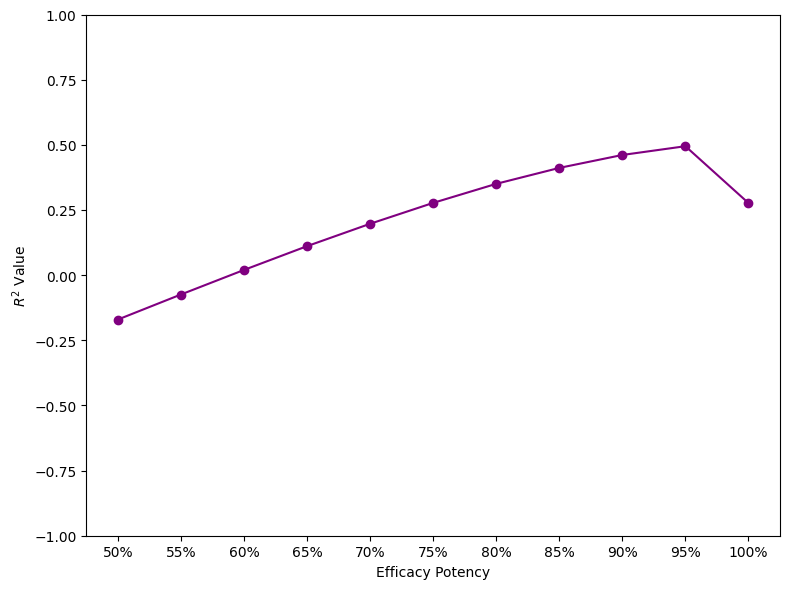

In [377]:
# Plotting the resulting R^2 values as a function of epsilon 
# R^2: how much of the pattern (observed vs. simulated) is captured 

plt.figure(figsize = (8, 6))
plt.plot(R2_results_df['Efficacy'],
         R2_results_df['R2'],
         marker = 'o',
         color = 'purple'
        )

plt.xlabel('Efficacy Potency')
plt.ylim(-1,1)
plt.ylabel('$R^2$ Value')
plt.xticks(R2_results_df['Efficacy'])
plt.grid(False)
plt.tight_layout()
plt.show()

In [380]:
print(simulated_difference)

[ 0.         -4.19310609 -3.02648828 -2.26110056 -1.64910864]


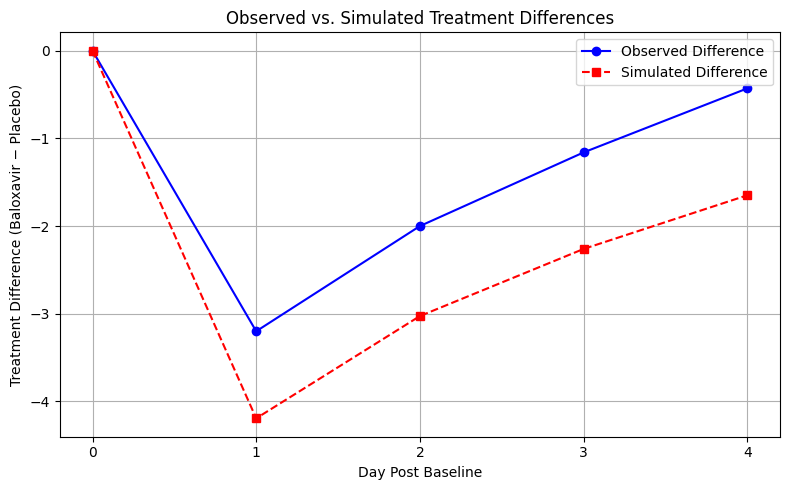

In [379]:
# plotting the observed vs simulated differences over time as well
days_to_analyze = [0, 1, 2, 3, 4
                   #, 5, 6
                  ]

plt.figure(figsize=(8, 5))

plt.plot(
    days_to_analyze,
    observed_difference,
    marker='o',
    linestyle='-',
    color='blue',
    label='Observed Difference'
)

plt.plot(
    days_to_analyze,
    simulated_difference,
    marker='s',
    linestyle='--',
    color='red',
    label='Simulated Difference'
)

plt.xlabel('Day Post Baseline')
plt.ylabel('Treatment Difference (Baloxavir − Placebo)')
plt.title('Observed vs. Simulated Treatment Differences')
plt.xticks(days_to_analyze)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [189]:
# Calculating RMSE

days_to_analyze = [0, 1, 2, 3, 4, 5, 6]                           # matching NEJM paper for days post baseline 1, 2, 3, 4, 5, 6, 9
efficacy_values = np.append(np.arange(0.5, 1, 0.05), 0.99)        # efficacy rate from 50% - 99% by increments of 5%

rmse_results = {}

for efficacy in efficacy_values:
    efficacy_label = f'{int(efficacy*100)}%'

    # extract simulated difference across all days from above
    simulated_difference = np.array([
        balox_placebo_results[f'Day {day}'].loc[
            'Simulated Difference',
            efficacy_label
        ]
        for day in days_to_analyze
    ])

   # Calculate rmse
    rmse = np.sqrt(np.mean((observed_diff - simulated_difference)**2))
               
    # store results for each efficacy labeling 
    rmse_results[efficacy_label] = rmse

rmse_results_df = pd.DataFrame(list(rmse_results.items()),
                                  columns = ['Efficacy Potency', 'RMSE']
                                 )

print(rmse_results_df)

   Efficacy Potency      RMSE
0               50%  2.169265
1               55%  2.233982
2               60%  2.304111
3               65%  2.380481
4               70%  2.462747
5               75%  2.553710
6               80%  2.657981
7               85%  2.778021
8               90%  2.918453
9               95%  3.097790
10              99%  3.344879


In [ ]:
# Simulating plots for all individuals n = 44 placebo treated
IDs = untreated_df.ID.unique()

t_baseline = 0                            # time of baseline measurement is at peak viral load
treat_start = 0                           # start treatment immediately following baseline measurement
treat_end_B =  treat_start + 3.5          # 3.5 days of baloxavir

#fig = plt.figure(figsize =(3.2,2), dpi = 300)
#plt.rcParams.update({'font.size': 6, 'axes.linewidth':.5})

N = 5250 #len(t)
M = len(IDs)

# Arrays to store values
V_untreated = np.zeros((M,N))
V_O = np.zeros((M,N))
V_OUB = np.zeros((M,N))
V_B = np.zeros((M,N))

# Vector to store baseline values
Baselines = []

for count,ID in enumerate(IDs):
    params_dict = GetParams(parameters_df, ID, style = 'mode')

    # ------------------------------------ #
    # Simulating the ODE system (Model 4) 
    # ------------------------------------ #
    t,y = Simulate(deriv, param_order, params_dict, init, 40, 10000)
    V = np.log10(np.maximum(y[:,4],0.1))
    V_untreated[count,:] = V
    
    # ------------------------------------
    ######## Determine individual peak viral load ########
    # ------------------------------------
    pk_ind = np.argmax(V)          # peak viral load
    tpk = t[np.argmax(V)]          # time of peak viral load 
    Baselines.append(pk_ind)       # append to 'Baselines' vector 
    
    # set individual timing
    t_baseline_temp = tpk + t_baseline

    # ------------------------------------
    ######## Plotting ########
    ####### Placebo Individual's baseline drop in gray    
    treat_start_temp = tpk + treat_start             # start of treatment for placebo at peak viral + '0' days
    treat_end_B_temp = tpk + treat_end_B             # start of treatment for balox

    # ------------------------------------
    # Simulating the treatment system (Model 4 with oselt) 
    # ------------------------------------
    # oseltamivir: V0 - oselt, VUB - unbounded
    tt,yt = SimulateTreatment(derivOseltamivir, param_order, params_dict, 
                                initTreatment, 40, 10000,
                                treat_start_temp, treat_end_O_temp, avg_efficacy)

    # ------------------------------------
    # Oselt all individual's baseline drop in orange 
    # ------------------------------------
    VO = np.log10(np.maximum(yt[:,4]+yt[:,5],0.1))                                      
    V_O[count,:] = VO
    # plt.plot(t-t_baseline_temp,VO,color ='tab:orange', alpha = 0.1, lw = 1)

    # Oselt unbounded virus: all individual's baseline drop in red
    VUB = np.log10(np.maximum(yt[:,5],0.1))           
    V_OUB[count,:] = VUB
    #plt.plot(t-t_baseline_temp,VUB,color ='tab:red', alpha = 0.1, lw = 1)

    #####################################################################
    ##### Simulating the treatment system (Model 4 with baloxavir) ######
    ####################################################################
    # baloxavir
    ttB,ytB = SimulateTreatment(derivBaloxavir, param_order, params_dict, 
                                initTreatment, 40, 10000, 
                                treat_start_temp, treat_end_B_temp, avg_efficacy)
    
    ####### Balox all individual's baseline drop in purple
    VB = np.log10(np.maximum(ytB[:,4]+ytB[:,5],0.1))
    V_B[count,:] = VB
    #plt.plot(t-t_baseline_temp,VB,color ='tab:purple', alpha = 0.1, lw = 1)
    

####################################################################
# Okay we need to align things by the individual baseline
N_tpts = 5250 # 3 weeks (21 days)
V_untreated_alligned = np.zeros((M,N_tpts))
V_B_alligned = np.zeros((M,N_tpts))        #balox
V_O_alligned = np.zeros((M,N_tpts))        #oselt
V_OUB_alligned = np.zeros((M,N_tpts))      #oselt unbded

####################################################################
## Calculating the individual's drop from baselines
for i in np.arange(0,M):
    baseline_ind = Baselines[i]
    V_untreated_alligned[i,:] = V_untreated[i,baseline_ind:baseline_ind+N_tpts]
    V_B_alligned[i,:] = V_B[i,baseline_ind:baseline_ind+N_tpts]
    V_O_alligned[i,:] = V_O[i,baseline_ind:baseline_ind+N_tpts]
    V_OUB_alligned[i,:] = V_OUB[i,baseline_ind:baseline_ind+N_tpts]

####################################################################
## Plotting the mean of the three treatment arms
## Note that the unbounded virus for oseltamivir arm (dashed line) should be the same as baloxavir 
## due to the same mechanism of action modeled by the ODE systems 
plt.plot(np.linspace(0,21,N_tpts), np.mean(V_untreated_alligned, axis = 0), color = 'tab:gray', lw = 2, label = 'Placebo')
plt.plot(np.linspace(0,21,N_tpts), np.mean(V_O_alligned, axis = 0), color = 'tab:orange', lw = 2, label = 'Oseltamavir')
plt.plot(np.linspace(0,21,N_tpts), np.mean(V_B_alligned, axis = 0), color = 'tab:purple', lw = 2, label = 'Baloxavir')
plt.plot(np.linspace(0,21,N_tpts), np.mean(V_OUB_alligned, axis = 0), color = 'tab:red', lw = 2, ls = ":", label = 'Oselt Ubd')


####################################################################
## Set plot characteristics
plt.xlim(0,10)
plt.ylim(-3,7)
plt.xticks(np.arange(0,11))
plt.xlabel('Days Relative to Baseline')
plt.ylabel('Viral Load (log10)')
plt.hlines(y = 0, xmin = 0, xmax = 10,alpha = 0.3, color ='k', ls = '--')
plt.legend(loc = "upper right")          # Display the legend
plt.title('Mean Mechanisms of Action on Viral Clearance Kinetics', fontsize=8) 
